In [ ]:
import sys
sys.path.insert(1, '../../.')
from params import p, p_cosmology
from transient_rates import phi_0, R_SFR, plot_rates

import numpy  as np
import matplotlib.pyplot as plt
import astropy.units as u

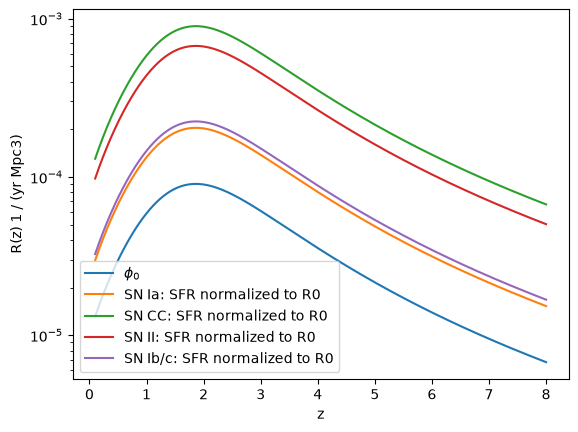

In [ ]:
z_range = np.linspace(0.1, 8, 1000)
r_z = R_SFR(z_range, R0=p_cosmology['R0']['SN Ia'], units=u.Mpc**-3*u.yr**-1)
plt.plot(z_range, phi_0(z_range), label=r'$\phi_0$')
plt.plot(z_range, r_z, label='SN Ia: SFR normalized to R0')
plt.plot(z_range, R_SFR(z_range, R0=p_cosmology['R0']['SN CC'], units=u.Mpc**-3*u.yr**-1), label='SN CC: SFR normalized to R0')
plt.plot(z_range, R_SFR(z_range, R0=p_cosmology['R0']['SN II'], units=u.Mpc**-3*u.yr**-1), label='SN II: SFR normalized to R0')
plt.plot(z_range, R_SFR(z_range, R0=p_cosmology['R0']['SN Ib/c'], units=u.Mpc**-3*u.yr**-1), label='SN Ib/c: SFR normalized to R0')
plt.yscale('log')
plt.legend()
plt.xlabel('z')
plt.ylabel(f'R(z) {r_z[0].unit}')
plt.show()


In [ ]:
import astropy.cosmology as acosmo

In [ ]:
cosmo = acosmo.LambdaCDM(H0=p_cosmology['h0']* u.km / u.s / u.Mpc, 
                         Om0= p_cosmology['omega_M'],
                        Ode0=p_cosmology['omega_L'])#, Tcmb0=2.725 * u.K,
help(cosmo.differential_comoving_volume)

Help on method differential_comoving_volume in module astropy.cosmology._src.flrw.base:

differential_comoving_volume(z: u.Quantity | ArrayLike, /) -> u.Quantity method of astropy.cosmology._src.flrw.lambdacdm.LambdaCDM instance
    Differential comoving volume at redshift z.

    Useful for calculating the effective comoving volume.
    For example, allows for integration over a comoving volume that has a
    sensitivity function that changes with redshift. The total comoving
    volume is given by integrating ``differential_comoving_volume`` to
    redshift ``z`` and multiplying by a solid angle.

    Parameters
    ----------
    z : Quantity-like ['redshift'], array-like
        Input redshift.

        .. versionchanged:: 7.0
            Passing z as a keyword argument is deprecated.

        .. versionchanged:: 8.0
           z must be a positional argument.

    Returns
    -------
    dV : Quantity
        Differential comoving volume per redshift per steradian at each
        

In [ ]:
import scipy

help(scipy.integrate.trapezoid)


Help on function trapezoid in module scipy.integrate._quadrature:

trapezoid(y, x=None, dx=1.0, axis=-1)
    Integrate along the given axis using the composite trapezoidal rule.

    If `x` is provided, the integration happens in sequence along its
    elements - they are not sorted.

    Integrate `y` (`x`) along each 1d slice on the given axis, compute
    :math:`\int y(x) dx`.
    When `x` is specified, this integrates along the parametric curve,
    computing :math:`\int_t y(t) dt =
    \int_t y(t) \left.\frac{dx}{dt}\right|_{x=x(t)} dt`.

    Parameters
    ----------
    y : array_like
        Input array to integrate.
    x : array_like, optional
        The sample points corresponding to the `y` values. If `x` is None,
        the sample points are assumed to be evenly spaced `dx` apart. The
        default is None.
    dx : scalar, optional
        The spacing between sample points when `x` is None. The default is 1.
    axis : int, optional
        The axis along which to int

In [ ]:
def get_N_k(R_z, z_max=10, R0=1, p=p_cosmology, time_window=None, sky_area=4*np.pi*u.sr):
    '''
    Computes the total number of transients up to a redshift of z_max assuming the sources follow
    the rate R_z(R_0)

    N [t^{-1}] = \int_0^{z_max} R(z)/(1+z) dV/dz dz
    
    Params:
    -------
    R_z: func, volumetric rate pf the functions. Should have format: R_z(z, R_0)
    time_window: astropy.unit float. It has  to have a time unit if given. 
    
    Returns
    -------
    N_k: float. If time window is given its in units of [#number of transients / yr]. If timew window is given, then it
        gives [#number of transients] '''

    #change R0 to correct units:
    R0 = R0.to(u.Mpc**-3 * u.yr ** -1)
    z_range = np.linspace(p['z_min'], z_max, 10000)

    cosmo = acosmo.LambdaCDM(H0=p_cosmology['h0']* u.km / u.s / u.Mpc, 
                         Om0=p_cosmology['omega_M'],
                        Ode0=p_cosmology['omega_L'])#, Tcmb0=2.725 * u.K,
    dVdz = cosmo.differential_comoving_volume(z_range)

    y = R_z(z_range, R0=R0) / (1 + z_range) * dVdz * sky_area
    # N_k = scipy.interpolate.interp1d(z_range, y)
    N_k = scipy.integrate.trapezoid(y, z_range)
    if time_window is not None:
        #check if its in [yr]
        if not isinstance(time_window, u.Quantity):
            "Time window given has no specified unit. Assuming [yr]"
            time_window = time_window * u.yr
        #change to yr if different
        time_window = time_window.to(u.yr)
        return N_k * time_window
    return N_k

<>:6: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:6: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
/var/folders/9g/fpz1sy1x4jbc8fm9s02wgv9c0000gn/T/ipykernel_3622/416654203.py:6: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  N [t^{-1}] = \int_0^{z_max} R(z)/(1+z) dV/dz dz


In [ ]:
np.format_float_scientific(get_N_k(R_SFR, R0=p_cosmology['R0']['SN Ia'], z_max=0.8, time_window=1*u.yr))

'4.780558245062894e+06'

In `FIRESONG` they compute the total number of transients up to a redshift $z_{max}$ as:
$$
N_{tot}(z\leq z_{max}) = R_0(z_{local})\cdot V_{c}(z\leq z_{local})\frac{\int_0^{z_{max}}\phi(z)/(1+z)\frac{dV_c}{dz}dz}{\int_0^{z_{local}}\phi(z)/(1+z)\frac{dV_c}{dz}dz}
$$

In [ ]:
def get_N_k_firesong(phi_z, R0, z_max=10, z_local=0.00023, p=p_cosmology, sky_area=4*np.pi*u.sr, time_window=None):

    R0 = R0.to(u.Mpc**-3 * u.yr ** -1)
    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                             Om0=p['omega_M'],
                            Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K,
    V_local = cosmo.comoving_volume(z_local)

    z_range_local = np.linspace(p['z_min'], z_local, 10000)
    z_range_max = np.linspace(p['z_min'], z_max, 10000)
    dVdz_max = cosmo.differential_comoving_volume(z_range_max)
    dVdz_local = cosmo.differential_comoving_volume(z_range_local)

    y_z_max = phi_z(z_range_max) * dVdz_max / (1 + z_range_max)
    y_z_local = phi_z(z_range_local) * dVdz_local / (1 + z_range_local) 

    N_k = R0 * V_local * scipy.integrate.trapezoid(y_z_max, z_range_max) / scipy.integrate.trapezoid(y_z_local, z_range_local) 
    if time_window is not None:
            #check if its in [yr]
            if not isinstance(time_window, u.Quantity):
                "Time window given has no specified unit. Assuming [yr]"
                time_window = time_window * u.yr
            #change to yr if different
            time_window = time_window.to(u.yr)
            return N_k * time_window
    return N_k

In [ ]:
value = get_N_k_firesong(phi_0, p_cosmology['R0']['SN Ia'], z_max=0.00023) / cosmo.comoving_volume(0.00023)
# np.format_float_.scientific(value)
print(value.to(u.Gpc ** -3 * u.yr ** -1))
print(np.format_float_scientific(value.to(u.Gpc ** -3 * u.yr ** -1).value))

23000.0 1 / (yr Gpc3)
2.3e+04


In [ ]:
print("R0:  ", p_cosmology['R0']['SN Ia'].to(u.Mpc**-3  * u.yr**-1))
cosmo.luminosity_distance(0.20)

R0:   2.2999999999999997e-05 1 / (yr Mpc3)


<Quantity 1015.62976066 Mpc>

In [ ]:
print("N up to z=1: ", get_N_k(R_SFR, R0=p_cosmology['R0']['SN Ia'], z_max=0.2, sky_area=4*np.pi*u.sr))
print("Average rate: ", get_N_k(R_SFR, R0=p_cosmology['R0']['SN Ia'], z_max=0.2, sky_area=4*np.pi*u.sr) / cosmo.comoving_volume(1))

N up to z=1:  73720.98704302002 1 / yr
Average rate:  4.4728251325573754e-07 1 / (yr Mpc3)


In [ ]:
p_test = p_cosmology.copy()
p_test['h0'] = 70
np.format_float_scientific(get_N_k_firesong(phi_0, p_cosmology['R0']['SN Ia'], z_max=1, time_window=465*u.d, p=p_test))

'1.1009317204865163e+07'

In [ ]:
p_test['h0']

70

In [ ]:
phi_0(1)

5.8923973513847306e-05

In [ ]:
import skysurvey

# 1. Initialize the Type Ia Supernova target model with zmax = 1.0
snia = skysurvey.SNeIa()

# 2. Draw targets for 1 year over the full sky (41,253 sq. deg.)
# skysurvey automatically integrates the volumetric rate over the sky area and time
snia.from_draw(nyears=1, zmax=1.0)

# 3. Access the total number of simulated Type Ia Supernovae
total_snia = len(snia.data)
print(f"Total SN Ia generated (1 year, full sky, z <= 1.0): {total_snia:,}")

# 4. Inspect the generated intrinsic parameters (redshift, peak time, stretch, color, etc.)
print(snia.data[["z", "t0", "x1", "c"]].head())

/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/ligo/skymap/bayestar/__init__.py:34: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


TypeError: object of type 'NoneType' has no len()

In [ ]:
help(snia)

In [ ]:
help(snia.draw)

Help on method draw in module skysurvey.target.core:

draw(
    size=None,
    zmax=None,
    zmin=0,
    tstart=None,
    tstop=None,
    nyears=None,
    skyarea=None,
    inplace=False,
    model=None,
    verbose=False,
    set_amplitude=False,
    **kwargs
) method of skysurvey.target.snia.SNeIa instance
    Draw the parameter model (using `self.model.draw()`).

    Parameters
    ----------
    size : int, optional
        Number of target you want to draw. Ignored is `nyears` is not
        None. By default None.
    zmax : float, optional
        Maximum redshift to be simulated. By default None.
    zmin : int, optional
        Minimum redshift to be simulated. By default 0.
    tstart : float, optional
        Starting time of the simulation. By default None.
    tstop : float, optional
        Ending time of the simulation. If `tstart` and `nyears` are both
        given, `tstop` will be overwritten by `tstart + 365.25 * nyears`.
        By default None.
    nyears : float, 

In [ ]:
data = snia.draw(nyears=1.27, zmax=1)
len(data)

4893813

In [ ]:
snia.get_rate(z=0)

23500.0

4.893813e+06


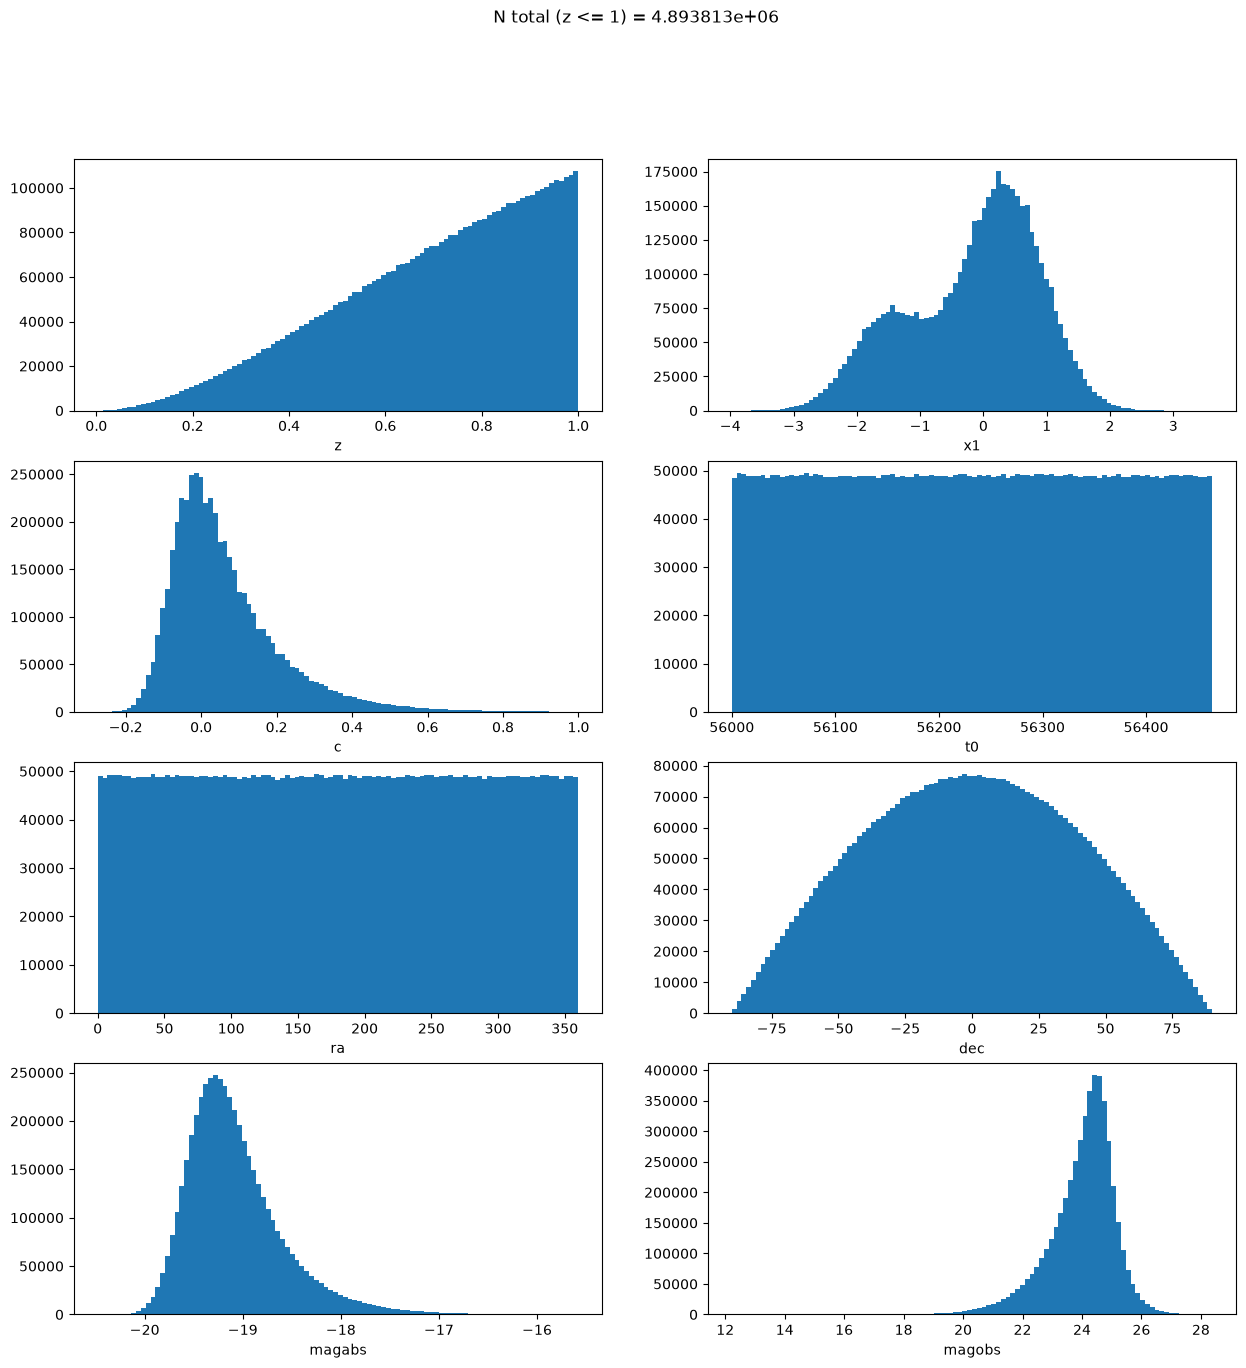

In [ ]:
print(np.format_float_scientific(len(data)))
fig, ax = plt.subplots(4, 2, figsize=(15,15))
n = 0
keys = list(data.keys())
for i in range(4):
    for j in range(2):
        ax[i][j].hist(data[keys[n]], bins=100)
        ax[i][j].set_xlabel(keys[n])
        n += 1 
plt.suptitle(f'N total (z <= 1) = {np.format_float_scientific(len(data))}')
plt.show()

In [ ]:
np.format_float_scientific(get_N_k_firesong(norm_phi_0, R0=p_cosmology['R0']['SN Ia'], z_max=1, time_window=1.27*u.yr))

V_local:  4.484187214048985 Mpc3


'1.2303135527319986e+07'

In [ ]:
def phi_0(z):
    return 0.0068*0.0015*(1 + z)**2.7/(1 + ((1 + z)/2.9)**5.6) 
    
def norm_phi_0(z, z_max=10, p=p_cosmology):
    return phi_0(z) / phi_0(0)

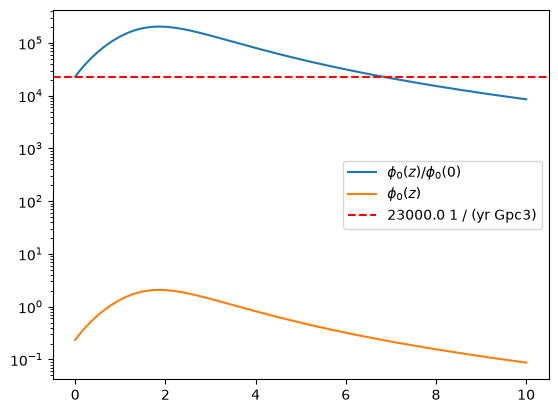

In [ ]:
z_range = np.linspace(0.001, 10, 1000)
R0 = p_cosmology['R0']['SN Ia'].to(u.Gpc**-3 * u.yr ** -1)
plt.plot(z_range, R0.value * norm_phi_0(z_range), label=r'$\phi_0(z)/\phi_0(0)$')
plt.plot(z_range, R0.value * phi_0(z_range), label=r'$\phi_0(z)$')
plt.axhline(R0.value, label=f'{R0}', c='red', linestyle='dashed')
plt.yscale('log')
plt.legend()
plt.show()

In [ ]:
help(cosmo)

Help on LambdaCDM in module astropy.cosmology._src.flrw.lambdacdm object:

class LambdaCDM(astropy.cosmology._src.flrw.base.FLRW)
 |  LambdaCDM(
 |      H0: astropy.cosmology._src.parameter.core.Parameter,
 |      Om0: astropy.cosmology._src.parameter.core.Parameter,
 |      Ode0: astropy.cosmology._src.parameter.core.Parameter,
 |      Tcmb0: astropy.cosmology._src.parameter.core.Parameter = Parameter(default=<Quantity 0. K>, derived=False, unit=Unit("K"), equivalencies=[], fvalidate='scalar', doc='Temperature of the CMB at z=0.'),
 |      Neff: astropy.cosmology._src.parameter.core.Parameter = Parameter(default=3.04, derived=False, unit=None, equivalencies=[], fvalidate='non-negative', doc='Number of effective neutrino species.'),
 |      m_nu: astropy.cosmology._src.parameter.core.Parameter = Parameter(default=<Quantity 0. eV>, derived=False, unit=Unit("eV"), equivalencies=[(Unit("kg"), Unit("J"), <function mass_energy.<locals>.<lambda> at 0x11a9c0720>, <function mass_energy.<locals

In [ ]:
unit = u.Mpc**-3